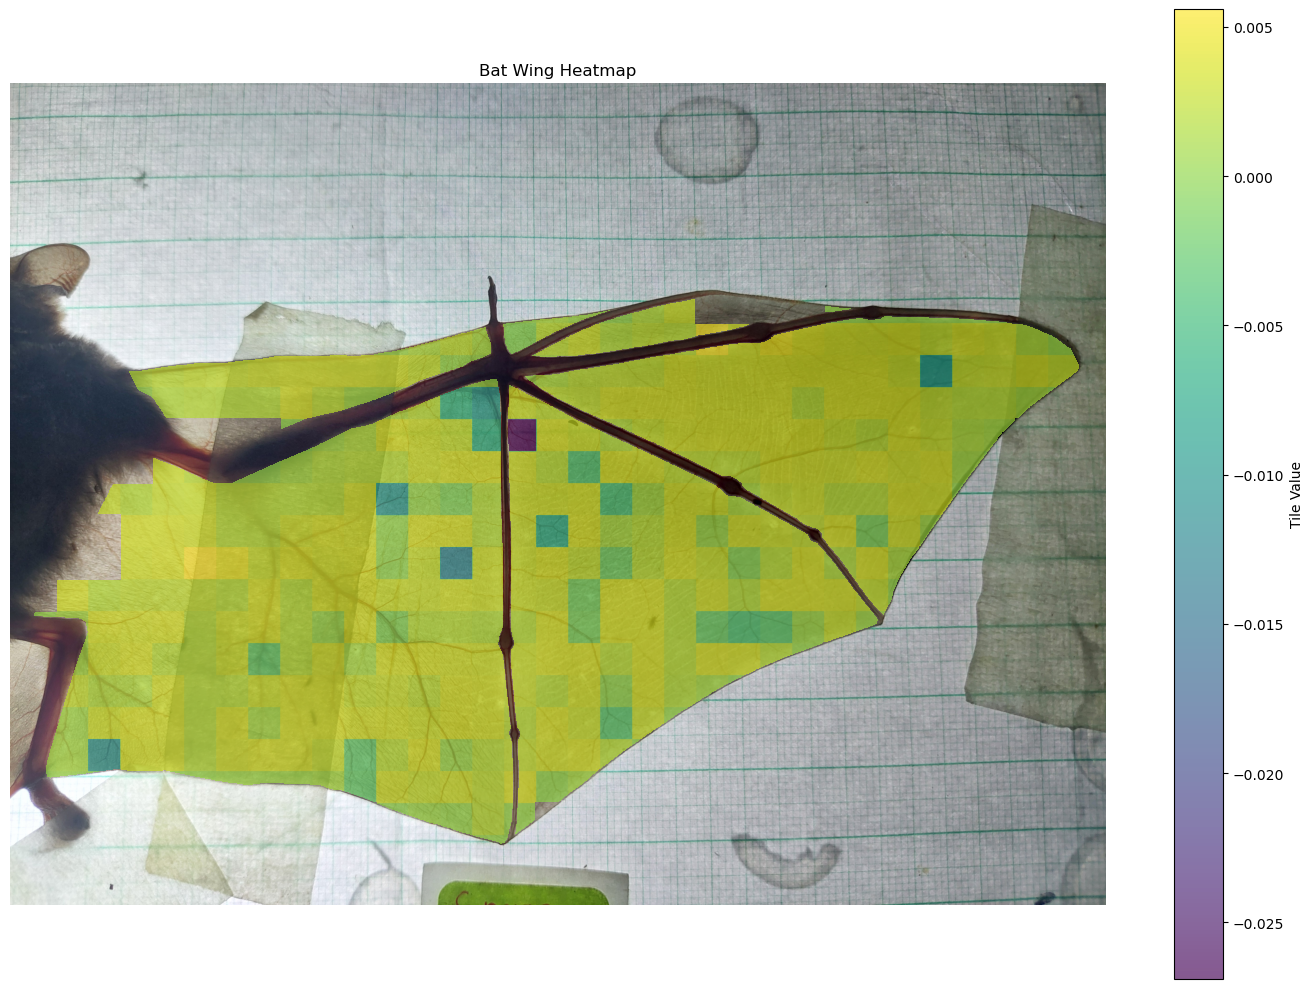

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_excel("Data_dQ.xlsx")
bg_img = Image.open("photos/Cperspicillata01.jpg")
mask_img = Image.open("masks/Cperspicillata01.png")

bg_w, bg_h = bg_img.size

TILE_W = 135
TILE_H = 135
X_OFFSET = 60 # Left margin px offset
Y_OFFSET = 68 # Top margin px offset

heatmap_canvas = np.full((bg_h, bg_w), np.nan)

# "Paint" each Excel value into its exact pixel block on the high-res canvas
for index, row in df.iterrows():
    
    # Calculate grid indices (matching top-down Y)
    col_idx = int(row["x"] - df["x"].min())
    row_idx = int(df["y"].max() - row["y"])
    
    # Calculate exact pixel boundaries for this specific tile
    x_start = X_OFFSET + (col_idx * TILE_W)
    x_end = x_start + TILE_W
    
    y_start = Y_OFFSET + (row_idx * TILE_H)
    y_end = y_start + TILE_H
    
    # Cap boundaries so we don't accidentally write outside the image size
    x_end = min(x_end, bg_w)
    y_end = min(y_end, bg_h)
    
    # Fill that pixel block with the heatmap value
    if y_start < bg_h and x_start < bg_w:
        heatmap_canvas[y_start:y_end, x_start:x_end] = row['dQ']

# ==========================================
# 4. APPLY THE PIXEL-PERFECT MASK
# ==========================================
mask_array = np.array(mask_img)

# Identify the positive mask areas. 
# Since the provided mask is bright blue, we can isolate the wing tissue by 
# checking where the Blue channel (index 2 in RGB) is highly active.
is_wing = mask_array[:, :, 2] > 50  

# Wherever the mask is NOT the wing (the background and the internal vessel structures),
# we erase the blocky heatmap data by setting those pixels back to NaN.
heatmap_canvas[~is_wing] = np.nan

# ==========================================
# 5. PLOT OVERLAY
# ==========================================
fig, ax = plt.subplots(figsize=(14, 10))

# Plot background normally
ax.imshow(bg_img, zorder=1)

# Plot the full-resolution, perfectly carved heatmap directly on top.
# We don't need 'extent' anymore because heatmap_canvas matches bg_image pixel-for-pixel.
heatmap = ax.imshow(heatmap_canvas, cmap='viridis', alpha=0.65, zorder=2)

plt.colorbar(heatmap, label='Tile Value')
plt.title('Bat Wing Heatmap')

# Hiding the axes looks much cleaner for this kind of morphological visualization
plt.axis('off') 
plt.tight_layout()
plt.show()